In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
#

In [15]:
make_blobs(
    n_samples=150,
    n_features=3,
    centers=4,
    cluster_std=0.5,
    shuffle=True,
    random_state=42
)

(array([[  4.35348428,  -9.60465749,   8.36447599],
        [ -9.30179299,   7.29376024,   0.40166656],
        [  1.03953709,  -6.5364971 ,  -7.68646753],
        [ -2.20335948,   9.52978589,   5.1055189 ],
        [ -8.94238888,   7.07702245,   1.72761786],
        [  4.15219499,  -9.73263943,   9.55955632],
        [ -8.524155  ,   7.31739953,   1.57367305],
        [ -8.91185645,   6.91077432,   1.86160731],
        [ -2.86022417,   8.85045505,   4.44382476],
        [ -9.85089905,   7.41675007,   1.691407  ],
        [ -8.52351334,   6.90902541,   1.74220971],
        [ -2.71952028,   8.84292887,   4.2387402 ],
        [  1.61599397,  -5.94673994,  -6.64319313],
        [ -8.38852782,   7.47717268,   2.42873129],
        [ -8.56477907,   7.22242659,   1.91345963],
        [  4.84576733, -10.07077184,   9.74122277],
        [  3.89857405,  -9.96787644,   9.47339394],
        [  2.45017057,  -6.55393157,  -7.03774422],
        [ -9.59801274,   7.08140588,   2.65575581],
        [  1

In [8]:
x,y = make_blobs(
    n_samples=150,
    n_features=3,
    centers=4,
    cluster_std=0.5,
    shuffle=True,
    random_state=42
)

In [10]:
x

array([[  4.35348428,  -9.60465749,   8.36447599],
       [ -9.30179299,   7.29376024,   0.40166656],
       [  1.03953709,  -6.5364971 ,  -7.68646753],
       [ -2.20335948,   9.52978589,   5.1055189 ],
       [ -8.94238888,   7.07702245,   1.72761786],
       [  4.15219499,  -9.73263943,   9.55955632],
       [ -8.524155  ,   7.31739953,   1.57367305],
       [ -8.91185645,   6.91077432,   1.86160731],
       [ -2.86022417,   8.85045505,   4.44382476],
       [ -9.85089905,   7.41675007,   1.691407  ],
       [ -8.52351334,   6.90902541,   1.74220971],
       [ -2.71952028,   8.84292887,   4.2387402 ],
       [  1.61599397,  -5.94673994,  -6.64319313],
       [ -8.38852782,   7.47717268,   2.42873129],
       [ -8.56477907,   7.22242659,   1.91345963],
       [  4.84576733, -10.07077184,   9.74122277],
       [  3.89857405,  -9.96787644,   9.47339394],
       [  2.45017057,  -6.55393157,  -7.03774422],
       [ -9.59801274,   7.08140588,   2.65575581],
       [  1.73048791,  -6.83869

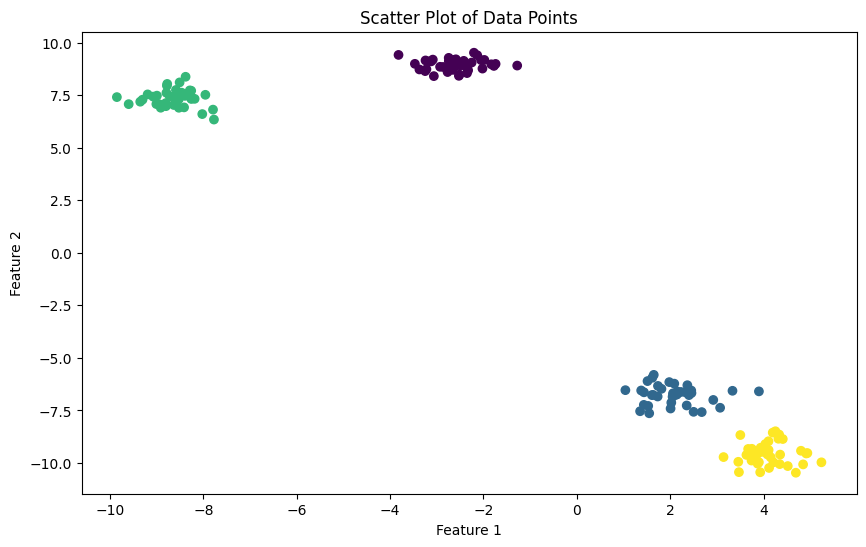

In [16]:
plt.figure(figsize=(10, 6))
plt.scatter(x[:, 0], x[:, 1], c=y, cmap='viridis')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Scatter Plot of Data Points')
plt.show()

In [18]:
model = KMeans(n_clusters=4, random_state=42)
model.fit(x)

KMeans(n_clusters=4, random_state=42)

In [19]:
centroide=model.cluster_centers_

In [20]:
centroide

array([[ 4.12518662, -9.5719677 ,  9.44844066],
       [-2.59962782,  8.95411374,  4.60592658],
       [ 2.07088235, -6.7708111 , -6.94597903],
       [-8.64763829,  7.35983835,  1.81167897]])

Text(0.5, 1.0, 'Scatter Plot of Data Points')

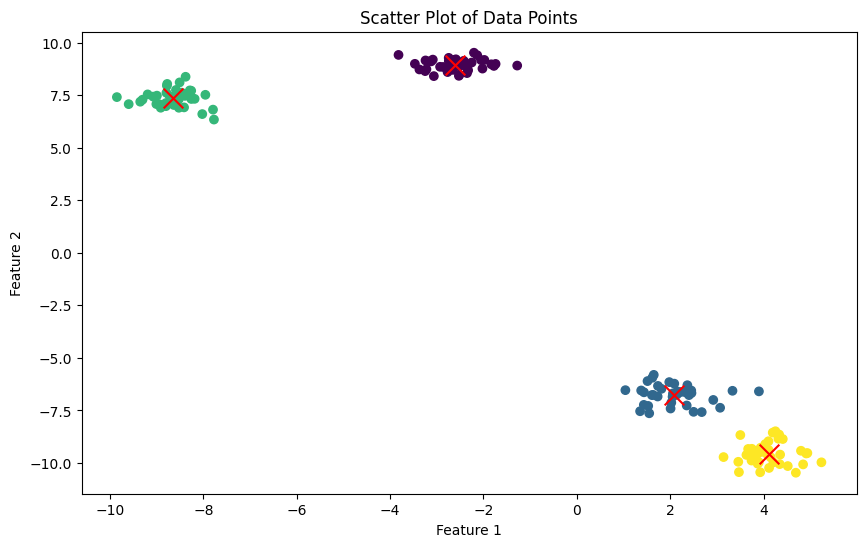

In [21]:
plt.figure(figsize=(10, 6))
plt.scatter(x[:, 0], x[:, 1], c=y, cmap='viridis')
plt.scatter(centroide[:, 0], centroide[:, 1], marker='x', color='red', s=200)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Scatter Plot of Data Points')

In [22]:
model.inertia_

100.93324484896769

In [32]:
k_values = range(2, 11)
inertia_values = []
silhouette_scores = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(x)
    inertia_values.append(model.inertia_)



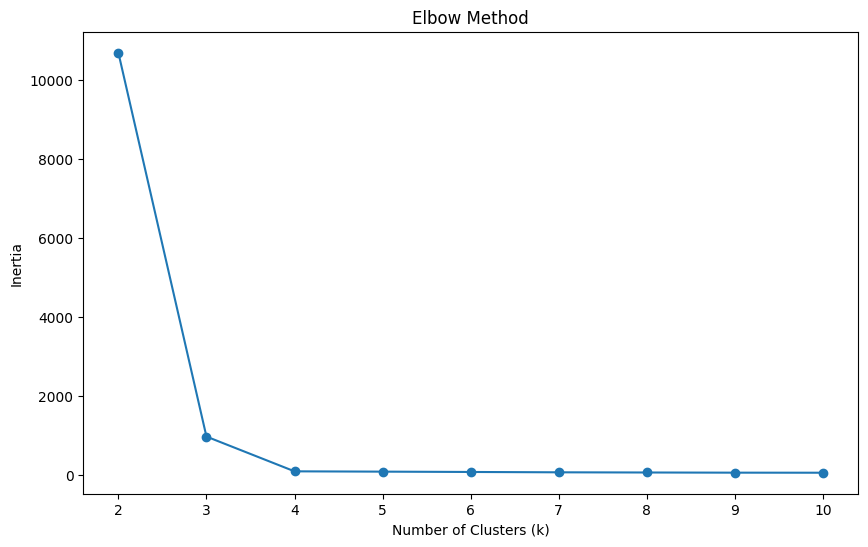

In [33]:
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertia_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [34]:
k_values = range(2, 11)
inertia_values = []
silhouette_scores = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(x)
    inertia_values.append(model.inertia_)



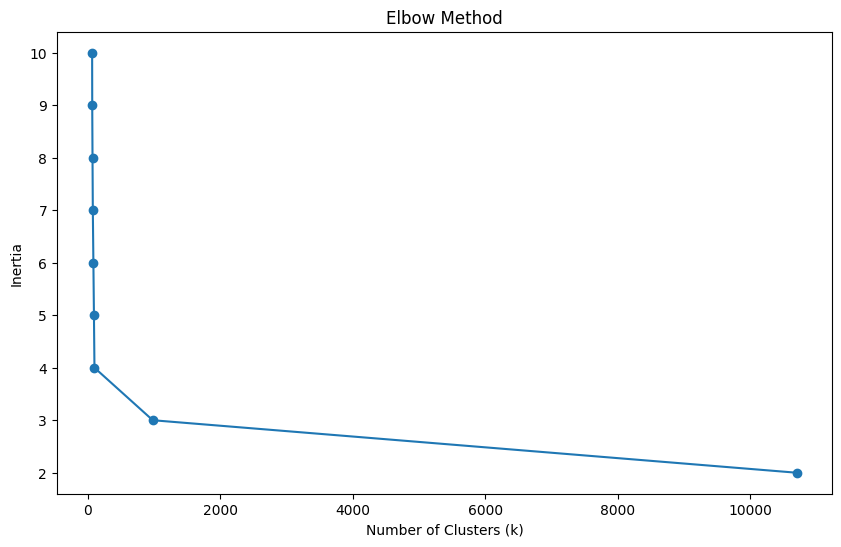

In [35]:
plt.figure(figsize=(10, 6))
plt.plot(inertia_values,k_values,  marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

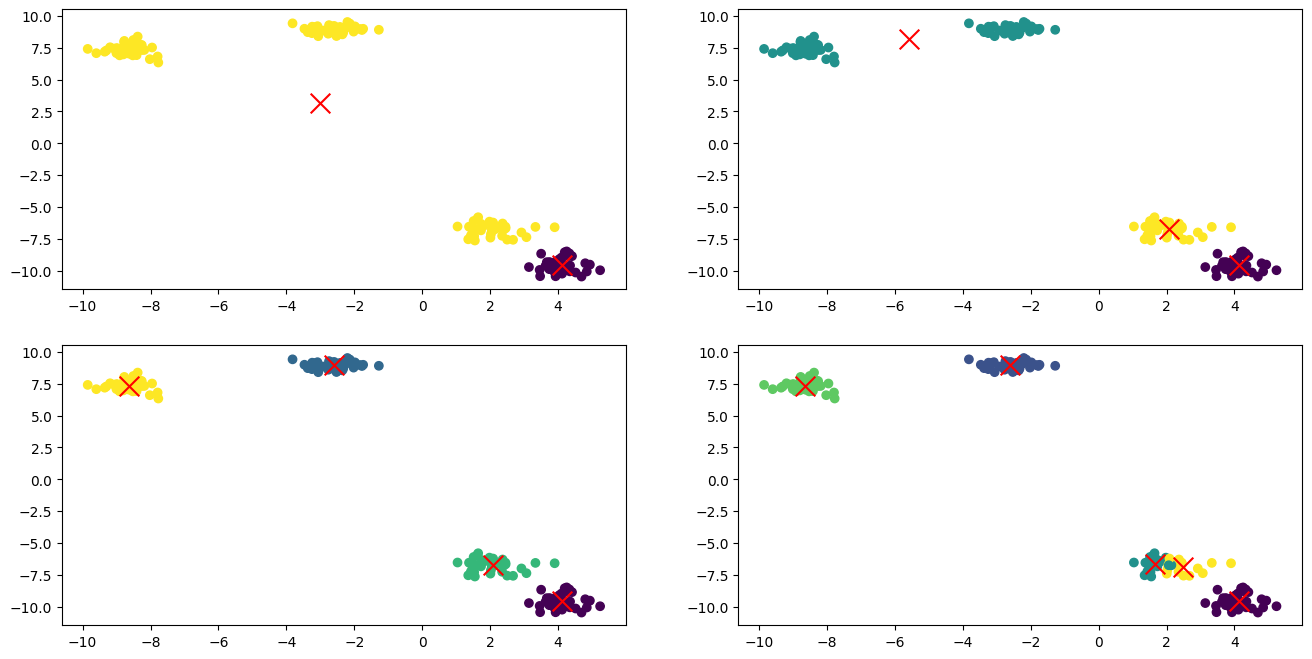

In [36]:
fig ,axes = plt.subplots(2,2,figsize=(16,8))
for ax ,k in zip(axes.flatten(),k_values):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(x)
    ax.scatter(x[:, 0], x[:, 1], c=model.labels_, cmap='viridis')
    ax.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker='x', color='red', s=200)